## Grapevine species and spotted lanternfly on the East Coast of the US in 2026

##### by Tojo Ramanitrera

### Introduction
Spotted lanternflies are invasive species in the *Lycorma* genus (an Asian planthopper genus). Their damage is mostly concentrated on tree of heaven plants (*Ailanthus altissima*), when they use their proboscis feeders to draw sap from the plants and leave , which ultimately leaves plants weak to further decay caused by disease or otherwise native preying insects (New York State Department of Environmental Conservation); they also create impediments to a plant's photosynthesis due to their sticky secretion which create ideal conditions which attracts other feeding insects and increases the growth of mold which further competes with the photosynthesizing plants (New York State Department of Environmental Conservation). They have first been observed in the United States in 2014 in Pennsylanvia and are also known to negatively impact vineyards and their grapevines due to their nymphs which, besides feeding on the various *Vitis* species, halt machinery (Penn State Extension). They are largely concentrated in the Northeast (Cornell University). Various analyses will be performed to see how lanternflies, geography (state), and *Vitis* species interact.

![lanternfly on top of grapevine](https://extension.psu.edu/media/wysiwyg//extensions/catalog_product/a8ad8859ca544e8096f6b8083e19e5b2/s/l/slf-adult-open-wings.jpg "a title")

(Credit: Penn State Extension, 'Spotted Lanternfly Management in Vineyards')

![Cornell IPM](https://raw.githubusercontent.com/fillymignon/Tojo-Ramanitrera-DATA101_Project2/refs/heads/main/Project_2/cornell_ipm.png "a title")

(Credit: Cornell University, 'Spotted Lanternfly Reported Distribution Map')
### Analysis and result
Data was collected from iNaturalist (a citizen scientist-sourced) and exported with the geographical and taxonomic information of all east-coast observations of spotted lanternflies (n=21621) and *vitis* grapevine species (n=6944) in 2026. Usernames and uuid were also both exported in order to credit contributors and also be able to index uniquely. A significance value of 0.05 was used for every test.

A chi-square test for relation (df=68) was performed in order to test whether states had an uniformly expected distribution of vitis species across states, and a null-rejecting decision was made against believing that all states had equal distributions of vitis species. This aligns with figure 1 ('Vitis species observations across various states')'s shape which although seemingly uniform, has varying frequencies of vitis species.

Then, two Pearsons' R test were performed: a test for whether lanternfly observations and state observations of vitis species were correlated, and a test for whether lanternfly observations were correlated with longitude.

The first returned a decision failing to reject the null hypothesis (indicating a lack of statistical evidence) that lantenrfly observations and vitis species were important, but a moderately strong negative r value was produced (r= -.31) indicating a negative linear correlation between the two.

The first returned a decision rejecting the null hypothesis (indicating statistical evidence) (p=0.01) that lantenrfly observations and longitude were important, and a very strong positive r value was produced (r= +.066) indicating a positive linear correlation between increase in longitude and spotted lanternfly observations


### Conclusion

Although, there is no found statistical evidence that certain vitis species were either more any differences in spotted lanternfly observations must not be assumed to be caused by their attraction to any vitis species but rather due to longitude and the geographical factors (temperature, humidity) associated with their migration area.

### References
Cornell University. (2026). *Spotted lanternfly status map - Cornell IPM*. Cornell Integrated Pest Management. https://maps.cornell-ipm.org/en/spotted-lanternfly/

New York State Department of Environmental Conservation. (n.d.). *Spotted lanternfly - NYDEC*. Retrieved October 27, 2026, from https://dec.ny.gov/nature/animals-fish-plants/spotted-lanternfly

Penn State Extension. (2025, April 10). *Spotted lanternfly management in vineyards*. https://extension.psu.edu/spotted-lanternfly-management-in-vineyards


In [202]:
# importing libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as st
from scipy.stats import f_oneway, pearsonr, chi2_contingency
# loading data
alpha = 0.05
df = pd.read_csv('lanternfly_observations.csv')
df2 = pd.read_csv('grapevine_observations.csv')

In [203]:
df.rename(columns={'place_state_name':'state'}, inplace=True) # renaming place state name species to just state
df = df.drop(['public_positional_accuracy'], axis=1) # removing redundant column
df['positional_accuracy'] = df['positional_accuracy'].fillna(df.groupby('state')['positional_accuracy'].transform('median')) #ensuring that positional accuracy is valid
df['user_name'] = df['user_name'].fillna('Anonymous') # filling in submissions without names as anonymous
df['description'] = df['description'].fillna('empty')
df = df.dropna() # dropping NaN's from df
df = df.drop_duplicates() # dropping duplicates from df
df['statelanternfly_counts'] = df.groupby('state')['taxon_id'].transform('count') # creating a
df.head(12)

,uuid,user_name,description,latitude,longitude,positional_accuracy,state,scientific_name,common_name,iconic_taxon_name,taxon_id,statelanternfly_counts
0,f62605f4-52b9-4dd6-b1ea-9a08bd7ab562,Anonymous,empty,40.943592,-76.598953,10.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
1,604b8367-be22-4408-91d3-0ef1934417b5,Anonymous,empty,40.943592,-76.598962,11.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
2,7a4cbeea-b138-4f58-9a62-308462223d36,James Weaver,empty,37.399703,-78.636792,9.0,Virginia,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,4243
3,bc4053a2-2f3b-420e-984e-694c1446caa3,Anonymous,empty,40.354717,-80.034447,11.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
4,196cfd71-075c-47e8-a749-b5ce4922ea95,Maggie Bartolovich,Now in a plastic bag with some hand sanitizer,39.079847,-84.675892,2014.0,Kentucky,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,176
5,24939ce5-4adb-4ecf-84d8-d6da3c874f99,Anonymous,empty,40.352669,-80.029708,5.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
6,263ff210-eb3d-4baf-92df-0576737c3145,Paweł Pieluszyński,empty,40.701389,-73.996834,11.0,New York,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,3360
7,fd5885da-deed-4b24-b3d4-003d92a7c85c,Cherie Cornmesser,empty,40.449225,-79.841242,11.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
8,2c060aff-11ab-4bf1-809a-df5874a6eade,Anonymous,empty,40.354858,-80.034425,11.0,Pennsylvania,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,2117
9,ae09c5e2-3c78-47b8-b35b-cc8818bc776c,Kevin Aviles,empty,41.818670,-71.413437,4.0,Rhode Island,Lycorma delicatula,Spotted Lanternfly,Insecta,324726,546


In [204]:
df2.rename(columns={'place_state_name':'state'}, inplace=True) # renaming place state name to just state
df2.rename(columns={'taxon_species_name':'species_name'}, inplace=True) # renaming taxonomy species to just species
df2['species_name'] = df2['species_name'].str[5:] # removing genus (vitis) from species name
df2['species_name'] = df2['species_name'].str.strip(' ') # removing whitespace from species name
df2['positional_accuracy'] = df2['positional_accuracy'].fillna(df.groupby('state')['positional_accuracy'].transform('median')) #ensuring that positional accuracy is valid
df2['user_name'] = df2['user_name'].fillna('Anonymous')
df2['description'] = df2['description'].fillna('empty') # filling in NaN's
df2.loc[df2['scientific_name']=='Vitis cinerea cinerea', 'common_name'] = 'graybark grape'
df2.loc[df2['scientific_name']=='Vitis cinerea cinerea', 'scientific_name'] = 'Vitis cinerea'
df2.loc[df2['scientific_name']=='Vitis cinerea baileyana', 'common_name'] = 'graybark grape'
df2.loc[df2['scientific_name']=='Vitis cinerea baileyana', 'scientific_name'] = 'Vitis cinerea'
df2.loc[df2['scientific_name']=='Vitis cinerea floridana', 'common_name'] = 'graybark grape'
df2.loc[df2['scientific_name']=='Vitis cinerea floridana', 'scientific_name'] = 'Vitis cinerea'# adding common name for vitis cinerea cinerea and merging at genus-species level (removing variations)
df2.loc[df2['scientific_name']=='Vitis rotundifolia rotundifolia', 'common_name'] = 'muscadine'
df2.loc[df2['scientific_name']=='Vitis rotundifolia rotundifolia', 'scientific_name'] = 'Vitis rotundifolia' # merging duplicate 'Muscadine' into 'muscadine' and merging at genus-species level (removing extra rotundifolia)
df2.loc[df2['scientific_name']=='Vitis aestivalis aestivalis', 'common_name'] = 'summer grape'
df2.loc[df2['scientific_name']=='Vitis aestivalis aestivalis', 'scientific_name'] = 'Vitis aestivalis' # merging duplicate 'Summer Grape' into 'summer grape and merging at genus-species level (removing extra aestivalis)
df2 = df2[df2['state']!='Ontario'] # Removing Ontario from data (not a US state)
df2 = df2.merge(df[['state','statelanternfly_counts']], on='state', how='right') # adding lanternfly state counts to df2
df2 = df2[df2['iconic_taxon_name']=='Plantae'] # ensuring all data are plants
df2 = df2.dropna() # dropping NaN's
df2 = df2.drop_duplicates() # dropping duplicates from df2
df2['statespecies_observations'] = df2.groupby(['state', 'species_name'])['uuid'].transform('count') # adding state-specific species counts
df2.head()

,uuid,user_name,description,latitude,longitude,positional_accuracy,state,scientific_name,common_name,iconic_taxon_name,taxon_id,species_name,statelanternfly_counts,statespecies_observations
1,d6b7431b-6e9b-4680-8efc-c116bfd8a2d1,Anonymous,empty,40.355544,-75.228747,4.0,Pennsylvania,Vitis vulpina,frost grape,Plantae,126645.0,vulpina,2117,12
2,3cc3d586-4337-488c-b670-00641491866f,Sara Rall,empty,40.379874,-74.958184,69.0,Pennsylvania,Vitis riparia,riverbank grape,Plantae,119936.0,riparia,2117,16
3,8d8bbfd7-dd0a-4a64-a532-a773f367f76a,Rebecca Turner,empty,42.016808,-80.378662,4.0,Pennsylvania,Vitis riparia,riverbank grape,Plantae,119936.0,riparia,2117,16
4,24265144-cd8a-4921-9a71-b3df39823165,Liam O,empty,39.884013,-75.262520,9.0,Pennsylvania,Vitis vulpina,frost grape,Plantae,126645.0,vulpina,2117,12
5,db6d67c4-6599-405d-9def-9a5bbecf874a,Anonymous,empty,40.554538,-80.206780,7.0,Pennsylvania,Vitis riparia,riverbank grape,Plantae,119936.0,riparia,2117,16


In [205]:
#list of unique vitis species
pd.unique(df2['species_name'])

<StringArray>
[     'vulpina',      'riparia',     'labrusca',   'aestivalis',
      'palmata', 'rotundifolia',      'cinerea',    'rupestris']
Length: 8, dtype: str

In [206]:
pd.crosstab(df2['species_name'], df2['state'])
print(table)
# Chi-square test of association
chi2, p_val, dof, expected = chi2_contingency(table)
print('A chi-square test of relation will be performed, checking if species are equally distributed over all states')
print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_val)
if p_val < alpha:
    print('Reject H0: there is statistically significant evidence that state and species are related: species are not equally distributed by state.')
else:
    print('Fail to reject H0: there is no statistically significant evidence that state and species are related: species are equally distributed by state.')
print("\nExpected Frequencies:\n", expected)


state         Alabama  Georgia  Illinois  Indiana  Kentucky  Maryland  \
species_name                                                            
aestivalis          0        0         0        0         0         0   
labrusca            0        0         0        0         0         0   
riparia             0        0        91       24         0         0   
rotundifolia      438      949         0        0        15        44   
vulpina             0       15         0        0         0         0   

state         Massachusetts  Michigan  Minnesota  New York  North Carolina  \
species_name                                                                 
aestivalis                0         0          0        21               0   
labrusca                 55         0          0        30               0   
riparia                  21       138        120       103               0   
rotundifolia              0         0          0         0             905   
vulpina             

In [207]:
df2['statespecies_observations'].max()

np.int64(949)

<Axes: title={'center': 'Vitis species observations across various states'}, xlabel='State', ylabel='Vitis observations'>

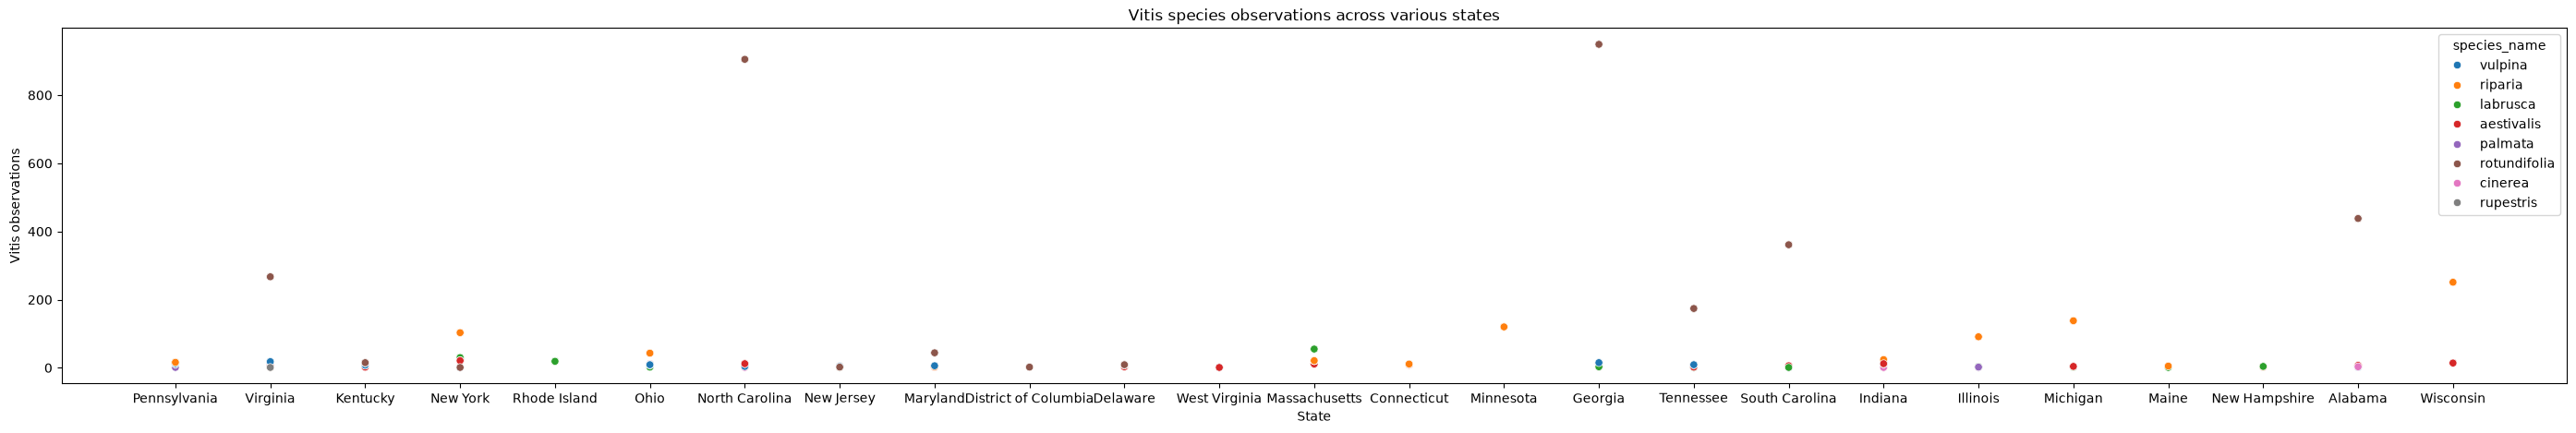

In [208]:
plt.figure(figsize=(35,5))
plt.title('Vitis species observations across various states')
plt.xlabel('State')
plt.ylabel('Vitis observations')
sns.scatterplot(
    data=df2,
    x='state',
    y='statespecies_observations',
    hue='species_name')

<Axes: title={'center': 'Lanternfly observations across states'}, xlabel='State', ylabel='Lanternfly observations'>

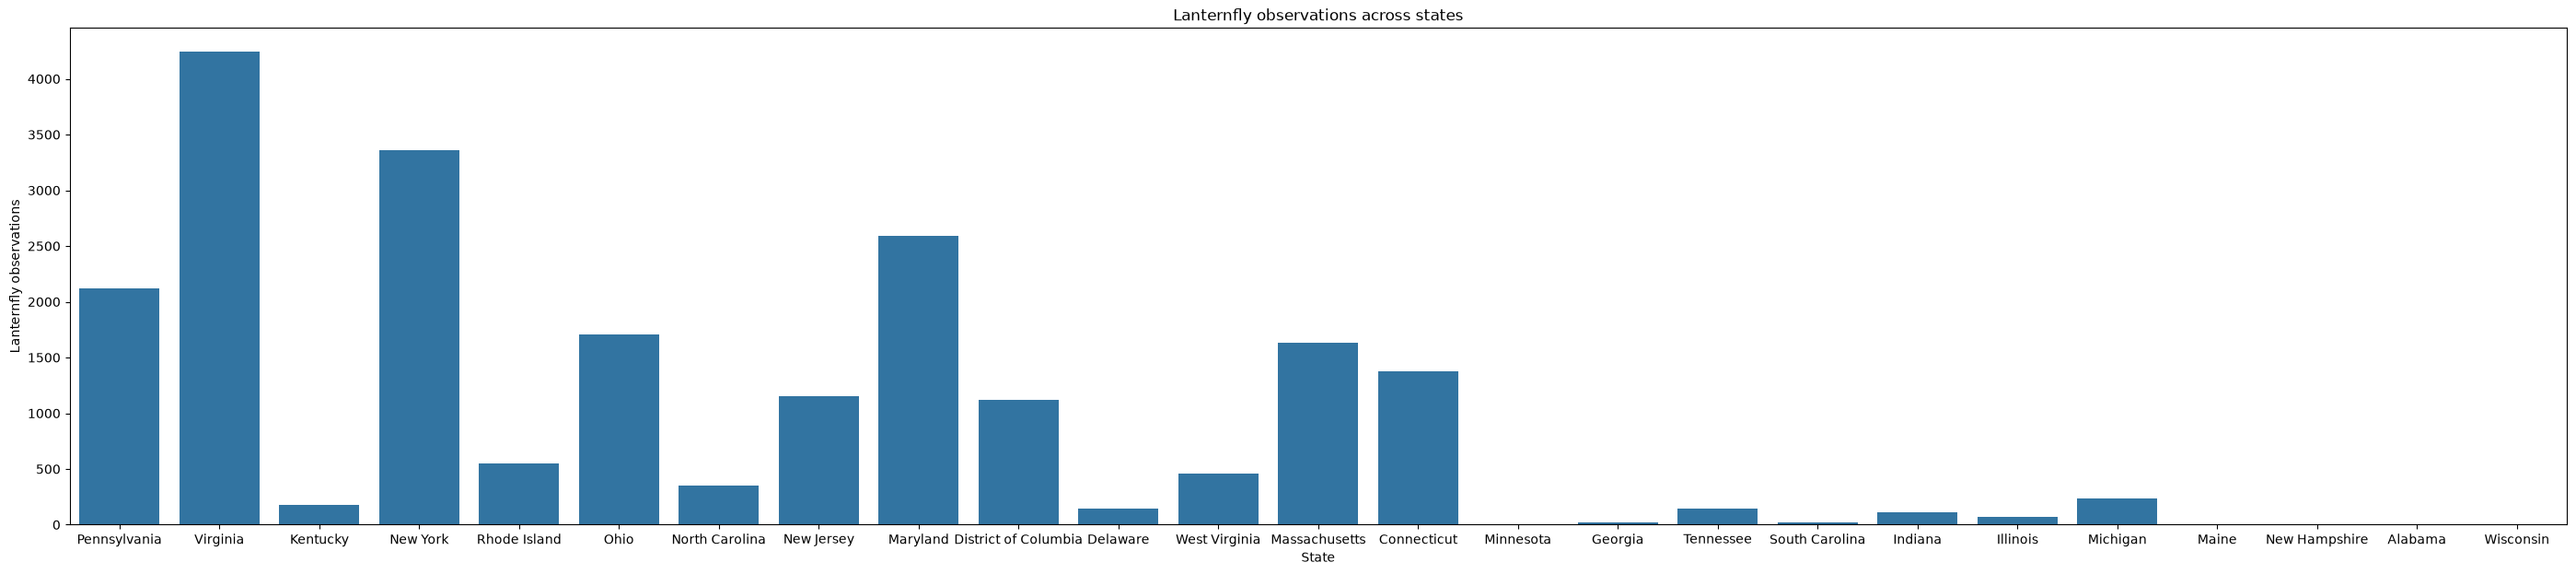

In [209]:
plt.figure(figsize=(35,7))
plt.title('Lanternfly observations across states')
plt.xlabel('State')
plt.ylabel('Lanternfly observations')
sns.barplot(
    data=df2,
    x='state',
    y='statelanternfly_counts')

<Axes: title={'center': 'Vitis species observations in Virginia'}, xlabel='Vitis species', ylabel='Observations'>

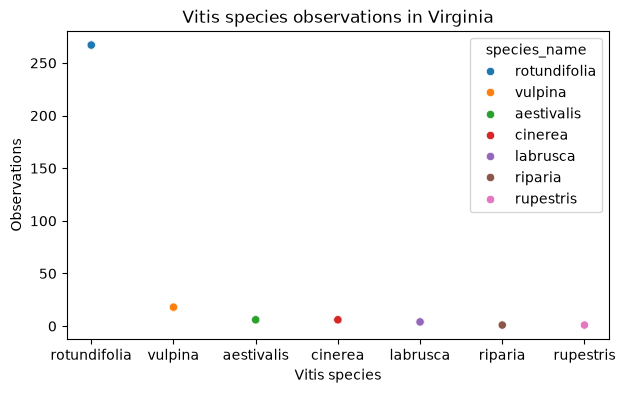

In [210]:
plt.figure(figsize=(7,4))
plt.title('Vitis species observations in Virginia')
plt.xlabel('Vitis species')
plt.ylabel('Observations')
sns.scatterplot(
    data=df2[df2['state']=='Virginia'],
    x='species_name',
    y='statespecies_observations',
    hue='species_name')

In [221]:
df2 = df2[df2['statespecies_observations']>=15] # dropping duplicates from df2
state_df = (df2.groupby('state').agg(statelanternfly_counts=('statelanternfly_counts', 'first'), statespecies_observations=('statespecies_observations', 'first'), state_longitude=('longitude', 'first')).reset_index())

r, p = st.pearsonr(state_df['statelanternfly_counts'],state_df['statespecies_observations'])

if p<alpha:
    print(f'The correlational coefficient between lanternfly observations and species observations is {r}, and there is statistically importance in vitis population sizes (p={p:.2f})')
else:
    print(f'The correlational coefficient between lanternfly observations and species observations is {r}, but there is no significant evidence that state lanternfly populations are statistically important in vitis population sizes (p={p:.2f})')

r, p = st.pearsonr(state_df['statelanternfly_counts'],state_df['state_longitude'])
if p<alpha:
    print(f'The correlational coefficient between lanternfly observations and state longtidue is {r}, and there is statistically importance in vitis population sizes (p={p:.2f})')
else:
    print(f'The correlational coefficient between lanternfly observations and state longitude is {r}, but there is no significant evidence that state lanternfly populations are statistically important in vitis population sizes (p={p:.2f})')



The correlational coefficient between lanternfly observations and species observations is -0.31327392405971083, but there is no significant evidence that state lanternfly populations are statistically important in vitis population sizes (p=0.26)
The correlational coefficient between lanternfly observations and state longtidue is 0.6583915902497149, and there is statistically importance in vitis population sizes (p=0.01)


<Figure size 2000x700 with 0 Axes>

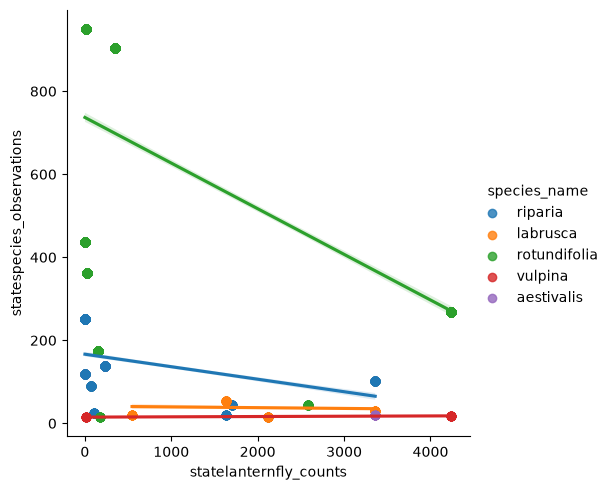

In [212]:
plt.figure(figsize=(20,7))
# Relation between state lanternfly observations and vitis species obervations
sns.lmplot(
    data=df2,
    x='statelanternfly_counts',
    y='statespecies_observations',
    hue='species_name')

In [213]:
df2 = df2[df2['statespecies_observations']>=20] # ANOVA test requires 20 or more samples
pd.unique(df2['species_name']) # species which do not have more than 20 samples will be dropped

<StringArray>
['rotundifolia', 'labrusca', 'riparia', 'aestivalis']
Length: 4, dtype: str

In [214]:
riparia_mean = df2[df2['species_name']=='riparia']['statelanternfly_counts']
labrusca_mean = df2[df2['species_name']=='labrusca']['statelanternfly_counts']
aestivalis_mean = df2[df2['species_name']=='aestivalis']['statelanternfly_counts']
rotundifolia_mean = df2[df2['species_name']=='rotundifolia']['statelanternfly_counts']
f_statistic, p_value = f_oneway(rotundifolia_mean, riparia_mean, labrusca_mean, aestivalis_mean)
print(f'F:statistic: {f_statistic}, P-value: {p_value}')
if p_value<alpha:
    print(f'There is statistically significant evidence that the state mean lanternfly population differs between vitis species(p={p_value:.2f})')
else:
    print(f'There is no statistically significant evidence that the state mean lanternfly population differs between vitis species(p={p_value:.2f})')

F:statistic: 100.70242707283049, P-value: 7.380026884688463e-63
There is statistically significant evidence that the state mean lanternfly population differs between vitis species(p=0.00)


In [217]:
# # A one-way ANOVA test will be performed

t_stat, t_pval = st.ttest_ind(rotundifolia_mean, riparia_mean)

print("--- Independent T-Test for riparia and rotundifolia lanternfly means ---")
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {t_pval:.2f}")
if t_pval < alpha:
    print("Reject H0 (Significant difference found)\n")
    if np.mean(rotundifolia_mean) > np.mean(riparia_mean):
        print (f"Rotundifolia (mean = {np.mean(rotundifolia_mean):.2f}) has more lanternflies than riparia (mean = {np.mean(riparia_mean):.2f}) \n")
    else:
        print (f"Riparia (mean = {np.mean(riparia_mean):.2f}) has more lanternflies than rotundifolia (mean = {np.mean(rotundifolia_mean):.2f}) \n")
else:
    print("Fail to reject H0\n")
t_stat, t_pval = st.ttest_ind(labrusca_mean, riparia_mean)
print("--- Independent T-Test for labrusca and riparia lanternfly means ---")
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {t_pval:.2f}")
if t_pval < alpha:
    print("Reject H0 (Significant difference found)\n")
    if np.mean(labrusca_mean) > np.mean(riparia_mean):
        print (f"Labrusca (mean = {np.mean(labrusca_mean):.2f}) has more lanternflies than riparia (mean = {np.mean(riparia_mean):.2f}) ")
    else:
        print (f"Riparia (mean = {np.mean(riparia_mean):.2f}) has more lanternflies than labrusca (mean = {np.mean(labrusca_mean):.2f}) ")
else:
    print("Fail to reject H0\n")
t_stat, t_pval = st.ttest_ind(aestivalis_mean, labrusca_mean)
print("--- Independent T-Test for aestivalis and labrusca lanternfly means ---")
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {t_pval:.2f}")
if t_pval < alpha:
    print("Reject H0 (Significant difference found)\n")
    if np.mean(aestivalis_mean) > np.mean(labrusca_mean):
        print (f"Aestivalis (mean = {np.mean(aestivalis_mean):.2f}) has more lanternflies than labrusca (mean = {np.mean(labrusca_mean):.2f}) ")
    else:
        print (f"Labrusca (mean = {np.mean(labrusca_mean):.2f}) has more lanternflies than aestivalis (mean = {np.mean(aestivalis_mean):.2f}) ")
else:
    print("Fail to reject H0\n")


--- Independent T-Test for riparia and rotundifolia lanternfly means ---
T-statistic: -2.37
P-value: 0.02
Reject H0 (Significant difference found)

Riparia (mean = 626.32) has more lanternflies than rotundifolia (mean = 515.31) 

--- Independent T-Test for labrusca and riparia lanternfly means ---
T-statistic: 12.60
P-value: 0.00
Reject H0 (Significant difference found)

Labrusca (mean = 2239.94) has more lanternflies than riparia (mean = 626.32) 
--- Independent T-Test for aestivalis and labrusca lanternfly means ---
T-statistic: 6.15
P-value: 0.00
Reject H0 (Significant difference found)

Aestivalis (mean = 3360.00) has more lanternflies than labrusca (mean = 2239.94) 
